# Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights
**Objective**: Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.

**Dataset**: This lab utilizes the Amazon UK product dataset
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

---

In [1]:
# Import needed libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
# Define the file path to the dataset and load it into a pandas DataFrame variable
file_path = r"D:\DSML\Week 2\Day 4\LABs\amz_uk_price_prediction_dataset.csv"
df = pd.read_csv(file_path)

In [3]:
# Cheking if the DataFrame was imported correctly
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 151.5 MB


---

## Part 1: Understanding Product Categories
**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:

   * Generate a frequency table for the product category.
   * Which are the top 5 most listed product categories?

2. **Visualizations**:

    * Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.
    * For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

In [5]:
# Generate a frequency table for the product category
category_counts = df["category"].value_counts() #Raw values (e.g., "400" )
category_proportions = df["category"].value_counts(normalize = True) * 100 #Percentage values (e.g., "2.3" % of 100%)

In [6]:
category_counts

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [7]:
category_proportions

category
Sports & Outdoors                         34.221949
Beauty                                     0.790293
Handmade Clothing, Shoes & Accessories     0.786896
Bath & Body                                0.781290
Birthday Gifts                             0.776625
                                            ...    
Motorbike Chassis                          0.004379
Alexa Built-In Devices                     0.004379
Plugs                                      0.004379
Smart Home Security & Lighting             0.004256
Smart Speakers                             0.002210
Name: proportion, Length: 296, dtype: float64

In [8]:
print(plt.colormaps())

['magma', 'inferno', 'plasma', 'viridis', 'cividis', 'twilight', 'twilight_shifted', 'turbo', 'berlin', 'managua', 'vanimo', 'Blues', 'BrBG', 'BuGn', 'BuPu', 'CMRmap', 'GnBu', 'Greens', 'Greys', 'OrRd', 'Oranges', 'PRGn', 'PiYG', 'PuBu', 'PuBuGn', 'PuOr', 'PuRd', 'Purples', 'RdBu', 'RdGy', 'RdPu', 'RdYlBu', 'RdYlGn', 'Reds', 'Spectral', 'Wistia', 'YlGn', 'YlGnBu', 'YlOrBr', 'YlOrRd', 'afmhot', 'autumn', 'binary', 'bone', 'brg', 'bwr', 'cool', 'coolwarm', 'copper', 'cubehelix', 'flag', 'gist_earth', 'gist_gray', 'gist_heat', 'gist_ncar', 'gist_rainbow', 'gist_stern', 'gist_yarg', 'gnuplot', 'gnuplot2', 'gray', 'hot', 'hsv', 'jet', 'nipy_spectral', 'ocean', 'pink', 'prism', 'rainbow', 'seismic', 'spring', 'summer', 'terrain', 'winter', 'Accent', 'okabe_ito', 'Dark2', 'Paired', 'Pastel1', 'Pastel2', 'Set1', 'Set2', 'Set3', 'tab10', 'tab20', 'tab20b', 'tab20c', 'grey', 'gist_grey', 'gist_yerg', 'Grays', 'magma_r', 'inferno_r', 'plasma_r', 'viridis_r', 'cividis_r', 'twilight_r', 'twilight_s

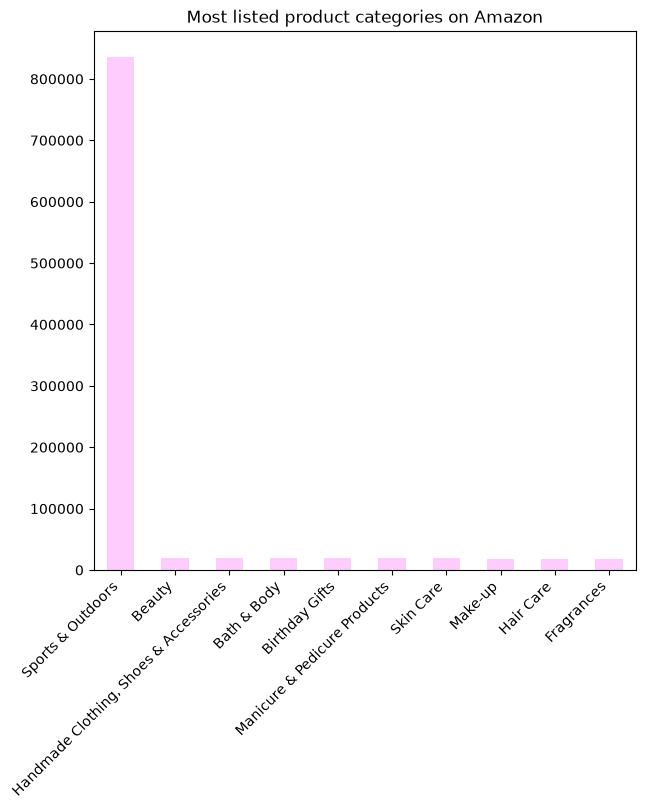

In [9]:
category_counts.head(10).plot.bar(
    colormap = "vanimo",
    figsize = (7, 7)
)

plt.title("Most listed product categories on Amazon")

plt.xlabel("")
plt.xticks(rotation = 45, ha = "right", va = "top")

plt.show()

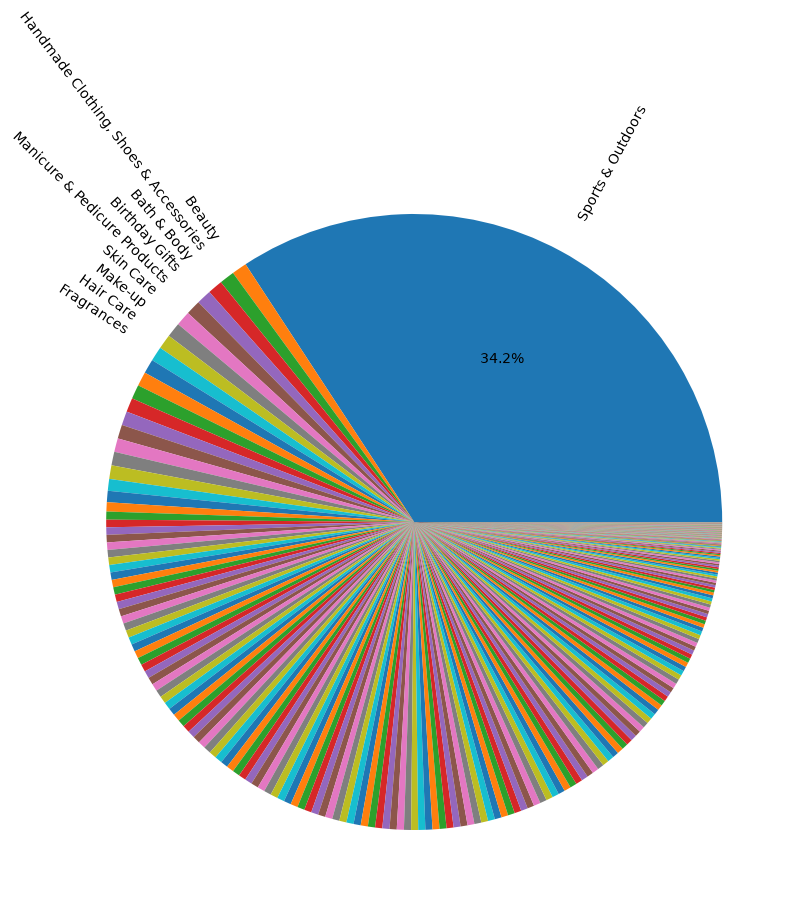

In [10]:
pie_clean_labels = [category if i < 10 else "" for i, category in enumerate(category_counts.index)]

category_counts.plot.pie(
    labels = pie_clean_labels,
    autopct = lambda p: f"{p:.1f}%" if p > 3 else "",
    figsize = (10, 10),
    rotatelabels = True
)

plt.show()

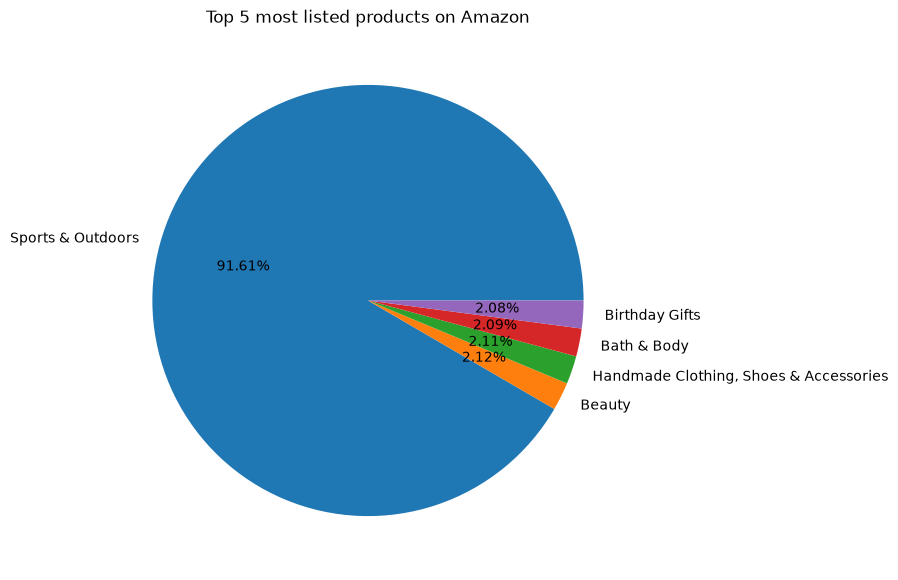

In [ ]:
# Pie chart based ONLY on the top 5 products

category_counts.head(5).plot.pie(
    autopct = lambda p: f"{p:.2f}%",
    figsize = (7, 7)
)


plt.title("Top 5 most listed products on Amazon")

plt.show()

---

##   Part 2: Delving into Product Pricing
**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:

    * Calculate the mean, median, and mode for the price of products.
    * What's the average price point of products listed? How does this compare with the most common price point (mode)?

2. **Measures of Dispersion**:

    * Determine the variance, standard deviation, range, and interquartile range for product price.
    * How varied are the product prices? Are there any indicators of a significant spread in prices?

3. **Visualizations**:

    * Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..
    * Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

In [20]:
mean_price = df["price"].mean()
median_price = df["price"].median()
mode_price = df["price"].mode()[0]

In [22]:
print("Mean price:", mean_price)        #Average price. Not very useful in this case.
print("Median price:", median_price)    #Exactly half of the items are priced under this number
print("Mode price:", mode_price)        #The most common price. The exact amount you'll most likely end up paying after buying an item.

Mean price: 89.24380943923661
Median price: 19.09
Mode price: 9.99


In [26]:
var_price = df["price"].var()
std_dev_price = df["price"].std()

min_price = df["price"].min()
max_price = df["price"].max()
range_price = max_price - min_price

Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
iqr_price = Q3 - Q1

In [115]:
print("Variance price:", var_price)
print("Standard deviation price:", std_dev_price)
print("Minimum price:", min_price)
print("Maximum price:", max_price)
print("Price range:", range_price)
print("Interquartile price range:", iqr_price)

Variance price: 119445.48532254901
Standard deviation price: 345.60886175349873
Minimum price: 0.0
Maximum price: 100000.0
Price range: 100000.0
Interquartile price range: 36.0


In [55]:
prices = df["price"]
prices

0          21.99
1          23.99
2          21.99
3          31.99
4          17.99
           ...  
2443646    22.34
2443647    97.99
2443648    52.99
2443649    79.99
2443650    53.99
Name: price, Length: 2443651, dtype: float64

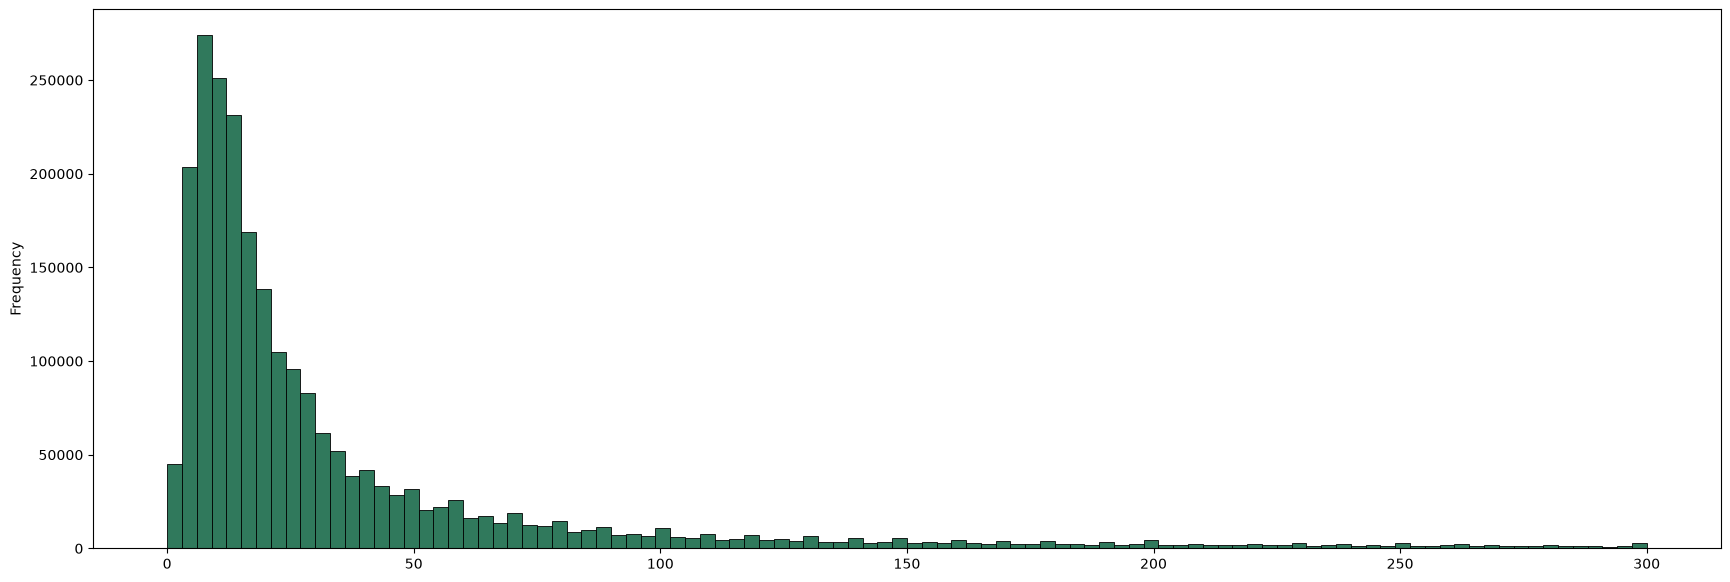

In [ ]:
prices.plot.hist(
    bins = 100,
    range = (0, 300),       #We add range so we only visualize the most significant values and have better visibility
    figsize = (21, 7),
    edgecolor = "black",
    color = "#30795C",
    linewidth = .6
)

plt.show()

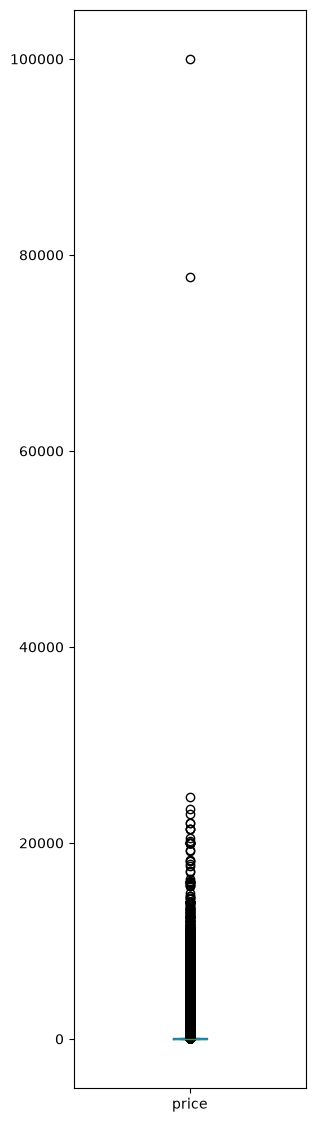

In [99]:
prices.plot.box(
    figsize = (3,14)
)

plt.show()

---

## Part 3: Unpacking Product Ratings
Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:

    * Calculate the mean, median, and mode for the rating of products.
    * How do customers generally rate products? Is there a common trend?

2. **Measures of Dispersion**:

    * Determine the variance, standard deviation, and interquartile range for product rating.
    * Are the ratings consistent, or is there a wide variation in customer feedback?

3. **Shape of the Distribution**:

    * Calculate the skewness and kurtosis for the rating column.
    * Are the ratings normally distributed, or do they lean towards higher or lower values?

4. **Visualizations**:

    * Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

In [123]:
#Remove unrated products
cleaned_stars = df["stars"].dropna()                #Remove blank ratings
cleaned_stars = cleaned_stars[cleaned_stars > 0]    #Minimum rating on Amazon is 1 star, so 0 is a placeholder

In [124]:
mean_rating = cleaned_stars.mean()
median_rating = cleaned_stars.median()
mode_rating = cleaned_stars.mode()[0]

In [125]:
print("Mean rating:", mean_rating)
print("Median rating:", median_rating)
print("Mode rating:", mode_rating) 

Mean rating: 4.319160762226911
Median rating: 4.4
Mode rating: 4.5


In [126]:
var_rating = cleaned_stars.var()
std_dev_rating = cleaned_stars.std()

min_rating = cleaned_stars.min()
max_rating = cleaned_stars.max()
range_rating = max_rating - min_rating

Q1 = cleaned_stars.quantile(0.25)
Q3 = cleaned_stars.quantile(0.75)
iqr_rating = Q3 - Q1

In [133]:
print("Variance rating:", var_rating)
print("Standard deviation rating:", std_dev_rating)
print("Minimum rating:", min_rating)
print("Maximum rating:", max_rating)
print("Rating range:", range_rating)
print("Interquartile rating range:", iqr_rating)

print("")
print("Looks like people rarely leave low ratings.")

Variance rating: 0.3083433752387284
Standard deviation rating: 0.5552867504620729
Minimum rating: 1.0
Maximum rating: 5.0
Rating range: 4.0
Interquartile rating range: 0.5

Looks like people rarely leave low ratings.


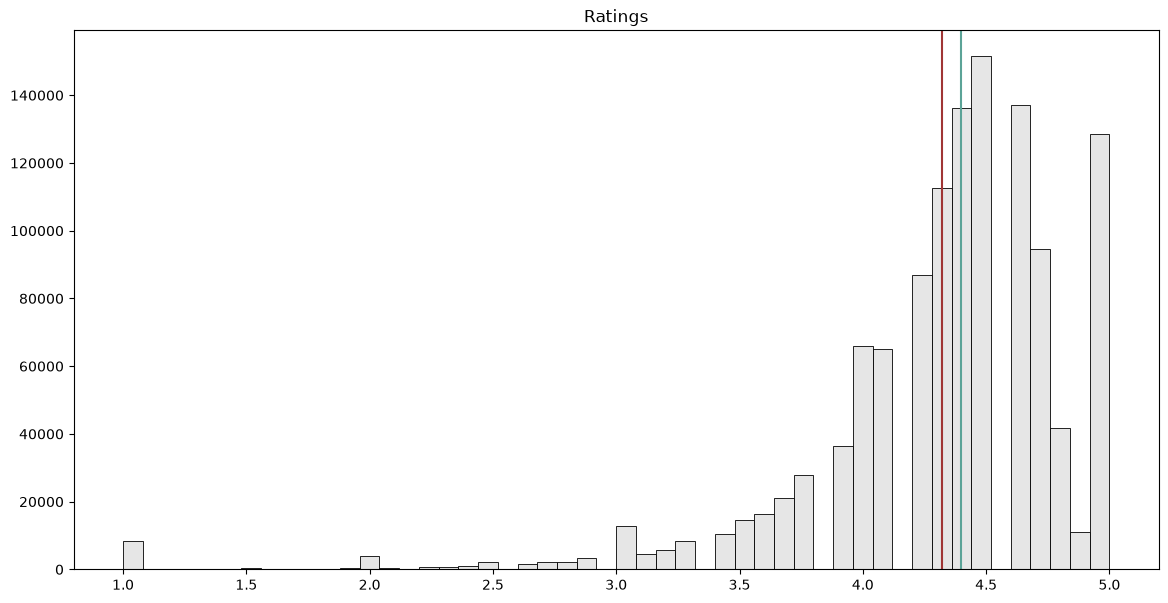

In [187]:
cleaned_stars.plot.hist(
    bins = 50,
    color = "#E6E6E6",
    edgecolor = "black",
    linewidth = .6,
    figsize = (14,7)
)

plt.axvline(mean_rating, color = "#A03535")
plt.axvline(median_rating, color = "#5BA397")

plt.title("Ratings")
plt.ylabel("")

plt.show()          #We can observe a clean negative skew, with a massive amount of reviews around 4.4 stars.

---

**Submission**: Submit a Jupyter Notebook which contains code and a business-centric report summarizing your findings.